# 🎓 Student Academic Risk Predictor

**Task:** Binary classification — flag students who may need academic support.
**Model:** Logistic Regression (tuned with grid search)
**Dataset:** `StudentPerformanceFactors.csv` (place it next to this notebook)
**Target:** `Needs_Support = 1` if `Exam_Score < 65`


---

## Table of Contents
1. Setup & Imports
2. Data Loading
3. Exploratory Data Analysis (EDA)
4. Data Preparation & Feature Selection
5. Train / Test Split
6. Preprocessing Pipeline
7. Model Building (Logistic Regression & why we chose it)
8. Cross-Validation & Hyperparameter Tuning
9. Test-Set Evaluation
10. Export the Model

---
# 1. Setup & Imports
Libraries for data handling, visualisation, preprocessing, modelling and evaluation.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score)

---
# 2. Data Loading
Read the CSV and check its shape and first rows.

In [3]:
path = "StudentPerformanceFactors.csv"
df = pd.read_csv(path)
print("Shape:", df.shape)
df.head()

Shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


---
# 3. Exploratory Data Analysis (EDA)
## 3.1 Dataset structure & data types

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

Split the columns into numeric and categorical groups.

In [5]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
print(f"Numeric columns ({len(numeric_cols)}):\n  {numeric_cols}")
print(f"\nCategorical columns ({len(categorical_cols)}):\n  {categorical_cols}")

Numeric columns (7):
  ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical columns (13):
  ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


## 3.2 Summary statistics
### Numeric features

In [6]:
display(df[numeric_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.98,5.99,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.98,11.55,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.03,1.47,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.07,14.40,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.49,1.23,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.97,1.03,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.24,3.89,55.0,65.0,67.0,69.0,101.0


### Categorical features

In [7]:
display(df[categorical_cols].describe().T)


,count,unique,top,freq
Parental_Involvement,6607,3,Medium,3362
Access_to_Resources,6607,3,Medium,3319
Extracurricular_Activities,6607,2,Yes,3938
Motivation_Level,6607,3,Medium,3351
Internet_Access,6607,2,Yes,6108
Family_Income,6607,3,Low,2672
Teacher_Quality,6529,3,Medium,3925
School_Type,6607,2,Public,4598
Peer_Influence,6607,3,Positive,2638
Learning_Disabilities,6607,2,No,5912


## 3.3 Data quality checks
### Missing values & duplicates

In [8]:
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0], "\n")
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()


Missing values:
 Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64 

Duplicate rows: 0


### Outlier check (box plots)

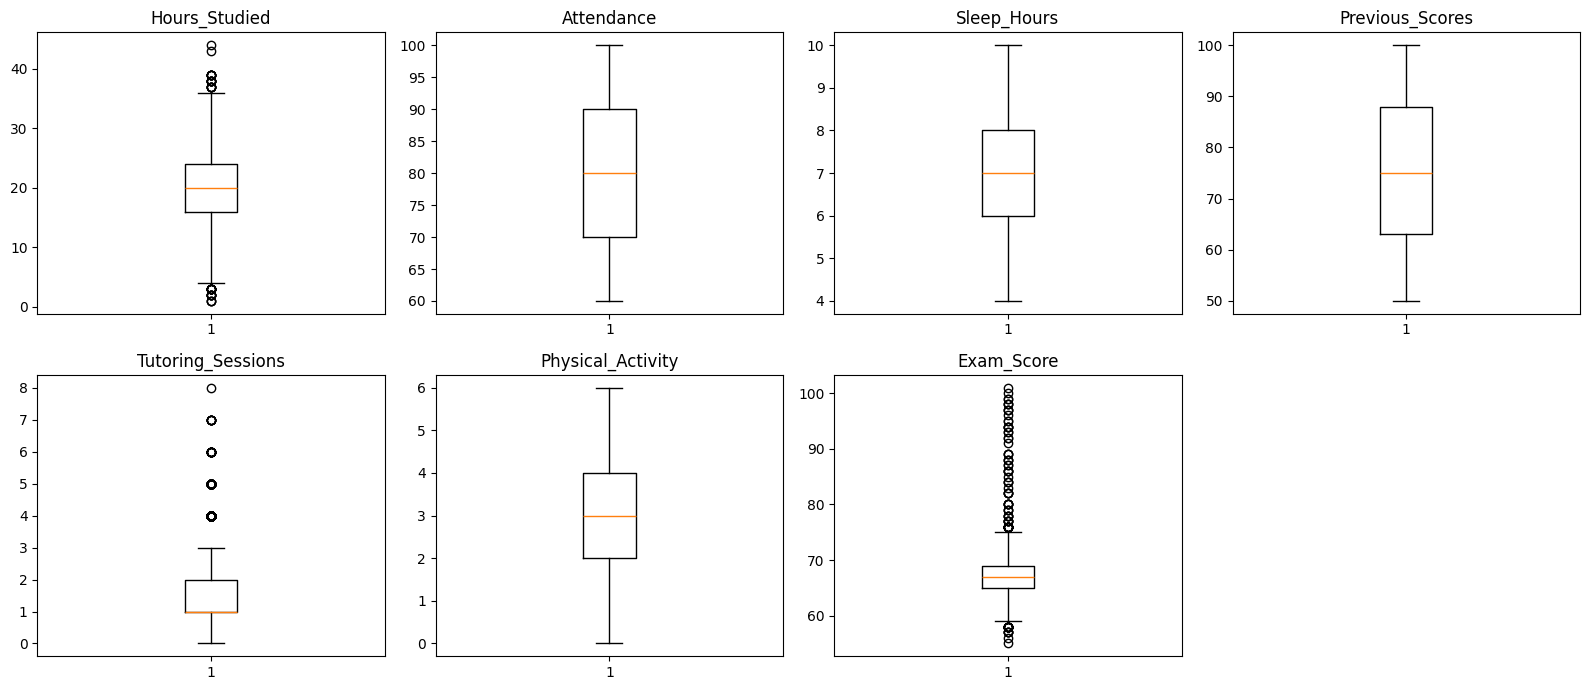

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()                      # turn the 2x4 grid into a flat list

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(df[col].dropna())    # draw the box plot for this column
    axes[i].set_title(col)

axes[-1].axis("off")                     # hide the empty 8th plot (we have 7 columns)

plt.tight_layout()
plt.show()

### Impossible `Exam_Score` values (> 100)

In [10]:
df[df['Exam_Score']>100].value_counts()

,,,,,,,,,,,,,,,,,,,,count
Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score,
27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101,1


## 3.4 Target creation
`Needs_Support = 1` if `Exam_Score < 65` (roughly the bottom ~22 % of students).

In [11]:
# "Needs support" = 1 if Exam_Score < 65 (roughly the bottom ~22% of students)
THRESHOLD = 65
df["Needs_Support"] = (df["Exam_Score"] < THRESHOLD).astype(int)
print("Class balance:\n", df["Needs_Support"].value_counts(normalize=True).round(3), "\n")

Class balance:
 Needs_Support
0    0.78
1    0.22
Name: proportion, dtype: float64 



In [12]:
target = "Needs_Support"

## 3.5 Target distribution (class balance)

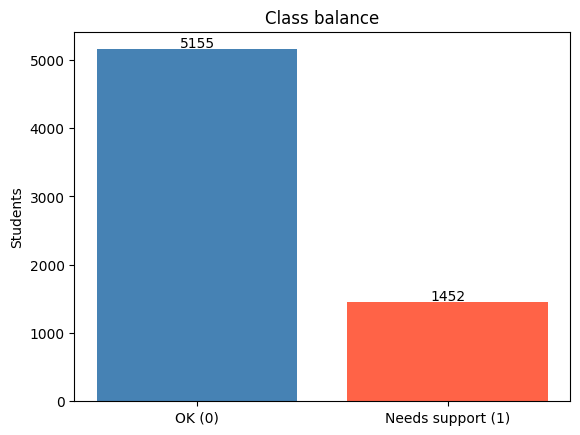

Needs_Support
0    78.0
1    22.0
Name: proportion, dtype: float64


In [13]:
counts = df[target].value_counts().sort_index()
plt.bar(["OK (0)", "Needs support (1)"], counts.values, color=["steelblue", "tomato"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 30, str(v), ha="center")
plt.title("Class balance")
plt.ylabel("Students")
plt.show()

print((df[target].value_counts(normalize=True) * 100).round(1))

## 3.6 Numeric features vs target

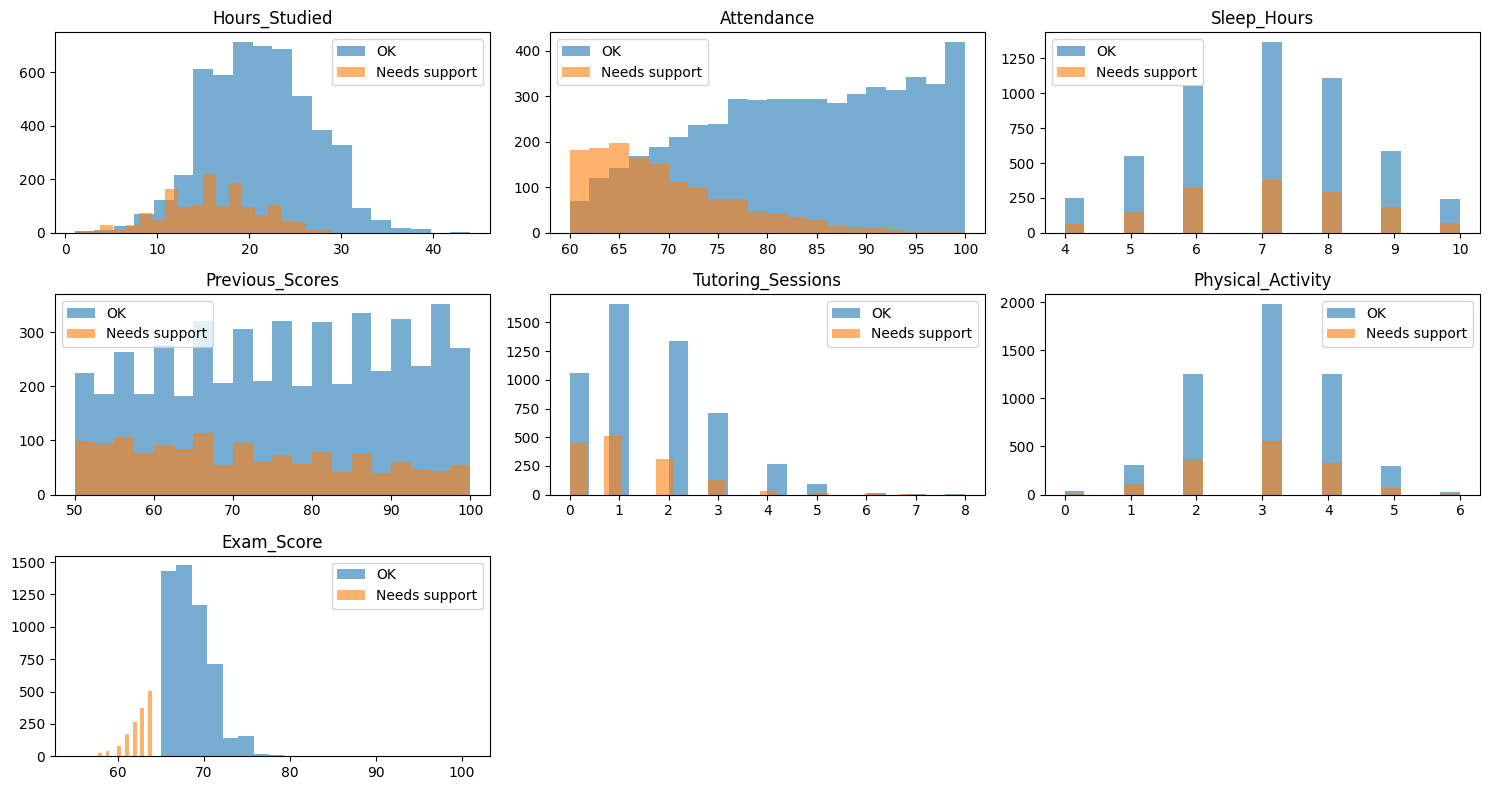

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[df[target] == 0][col], bins=20, alpha=0.6, label="OK")
    axes[i].hist(df[df[target] == 1][col], bins=20, alpha=0.6, label="Needs support")
    axes[i].set_title(col)
    axes[i].legend()

for ax in axes[len(numeric_cols):]:          # hide unused plots
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3.7 Categorical features vs target
Percentage of students needing support within each category.

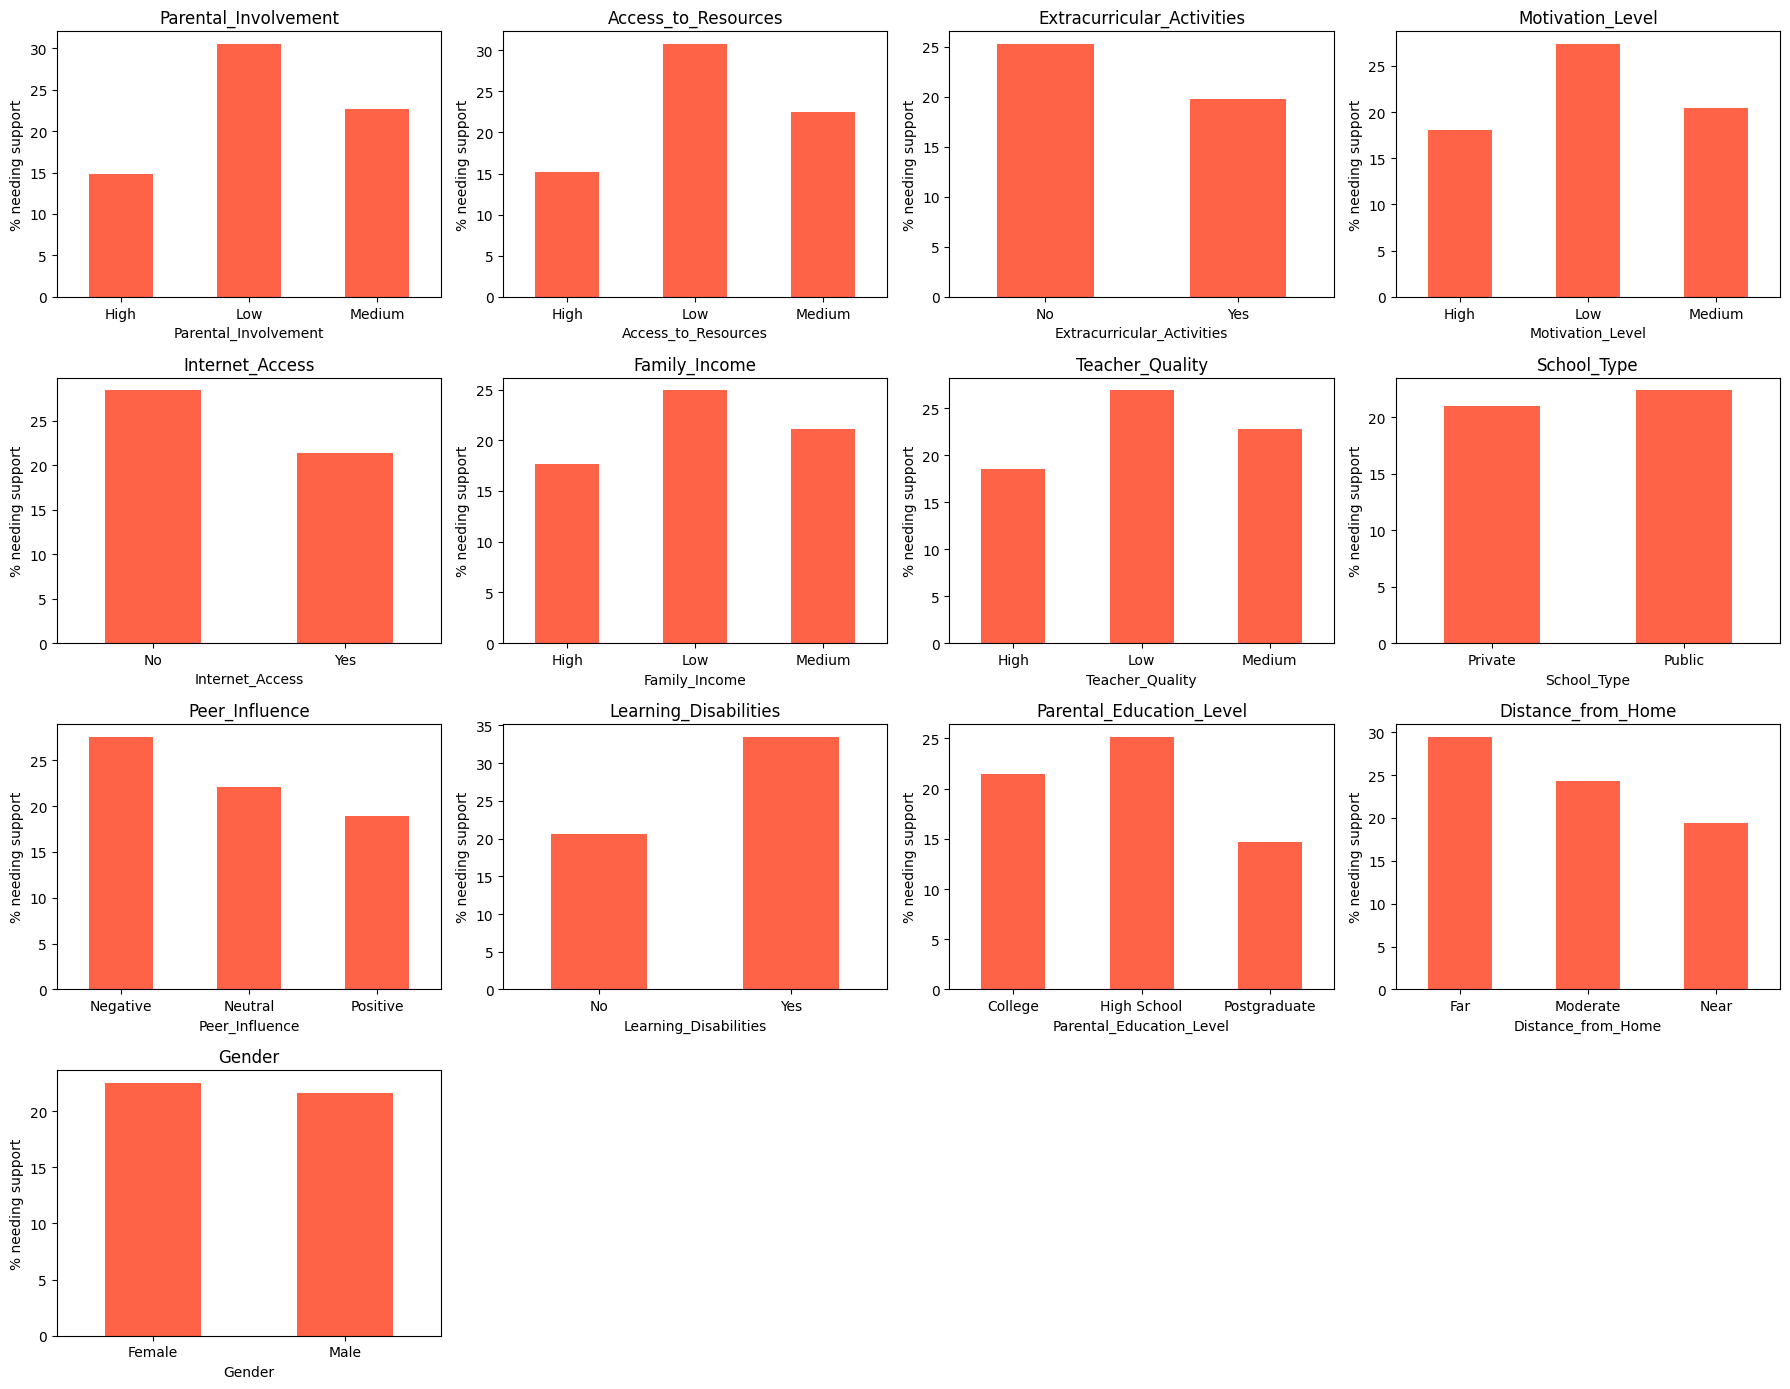

In [17]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.ravel()

for i, col in enumerate(categorical_cols):
    rate = df.groupby(col)[target].mean() * 100
    rate.plot.bar(ax=axes[i], rot=0, color="tomato")
    axes[i].set_title(col)
    axes[i].set_ylabel("% needing support")

for ax in axes[len(categorical_cols):]:          # hide unused plots
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3.8 Correlation analysis

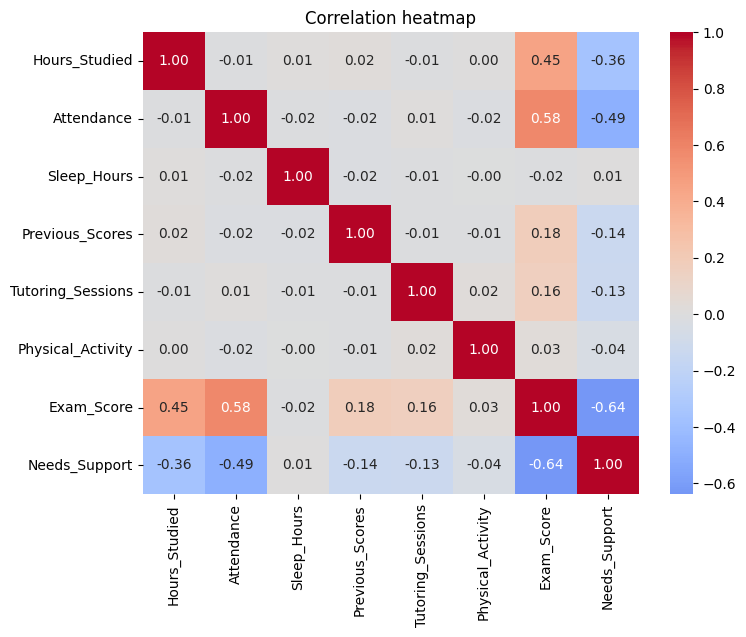

Exam_Score          -0.638463
Attendance          -0.493896
Hours_Studied       -0.359962
Previous_Scores     -0.136379
Tutoring_Sessions   -0.130963
Physical_Activity   -0.037918
Sleep_Hours          0.005180
Name: Needs_Support, dtype: float64


In [18]:
corr = df[numeric_cols + [target]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

print(corr[target].drop(target).sort_values())

## 3.9 EDA Conclusions
- **Data quality is good:** 6,607 rows, no duplicates, and only three columns (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`) have a few missing values, which can be imputed; one `Exam_Score` of 101 needs capping.
- **Classes are imbalanced (78 % OK vs 22 % needs support),** so class weighting and recall/F1 are more informative than plain accuracy.
- **Attendance (r ≈ -0.49) and Hours Studied (r ≈ -0.36) are the strongest behavioural signals;** Sleep Hours and Physical Activity show almost no relationship, and `Exam_Score` must be excluded from the features because the target is derived from it (leakage).

---
# 4. Data Preparation & Feature Selection
## 4.1 Cap impossible exam scores

In [19]:
df["Exam_Score"] = df["Exam_Score"].clip(upper=100)

## 4.2 Choose features
- `Exam_Score` is dropped to avoid **data leakage**.
- `Gender` is excluded on purpose (protected attribute).
- Columns are grouped into ordinal, nominal and numeric features.

In [21]:
target = "Needs_Support"
drop_cols = ["Exam_Score", "Gender", target]
X = df.drop(columns=drop_cols)
y = df[target]

ordinal_cols = {  # columns with a natural order
    "Parental_Involvement": ["Low", "Medium", "High"],
    "Access_to_Resources": ["Low", "Medium", "High"],
    "Motivation_Level": ["Low", "Medium", "High"],
    "Family_Income": ["Low", "Medium", "High"],
    "Teacher_Quality": ["Low", "Medium", "High"],
    "Parental_Education_Level": ["High School", "College", "Postgraduate"],
    "Distance_from_Home": ["Near", "Moderate", "Far"],
}
nominal_cols = ["Extracurricular_Activities", "Internet_Access", "School_Type",
                "Peer_Influence", "Learning_Disabilities"]
numeric_cols = ["Hours_Studied", "Attendance", "Sleep_Hours", "Previous_Scores",
                "Tutoring_Sessions", "Physical_Activity"]

---
# 5. Train / Test Split
80 / 20 split, stratified so both sets keep the same class balance.

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train, X_test = X_train.copy(), X_test.copy()

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Needs support in train:", round(y_train.mean(), 3))
print("Needs support in test: ", round(y_test.mean(), 3))

Train: (5285, 18)  Test: (1322, 18)
Needs support in train: 0.22
Needs support in test:  0.22


---
# 6. Preprocessing Pipeline
Imputation, scaling and encoding wrapped in a `ColumnTransformer` (fitted on training data only inside the pipelines).

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# 1. Extract ordinal column names and category order from your dictionary
ordinal_column_names = list(ordinal_cols.keys())
ordinal_categories = list(ordinal_cols.values())

# 2. Define individual pipelines for each column type
numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),  # Remove or adjust if scaling is conditional
    ]
)

ordinal_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(categories=ordinal_categories)),
    ]
)

nominal_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(drop="if_binary", handle_unknown="ignore"),
        ),
    ]
)

# 3. Combine pipelines in ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_cols),
        ("ord", ordinal_pipeline, ordinal_column_names),
        ("nom", nominal_pipeline, nominal_cols),
    ],
    remainder="passthrough",
)

---
# 7. Model Building

## 7.1 Define the pipeline
Preprocessing and the model are combined in one `Pipeline`, so exactly the same steps are applied at training time, at test time and after export.

In [31]:
log_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])

tree_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(class_weight="balanced", max_depth=4, random_state=42)),
])

## 7.2 Fit & baseline accuracy

In [32]:
log_pipe.fit(X_train, y_train)
tree_pipe.fit(X_train, y_train)

print("Logistic Regression accuracy:", round(log_pipe.score(X_test, y_test), 3))
print("Decision Tree accuracy:      ", round(tree_pipe.score(X_test, y_test), 3))

Logistic Regression accuracy: 0.979
Decision Tree accuracy:       0.821


---
# 8. Cross-Validation & Hyperparameter Tuning
## 8.1 Stratified 5-fold cross-validation (recall)

In [33]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
s = cross_val_score(log_pipe, X_train, y_train, cv=cv, scoring="recall")
print(f"Logistic Regression: CV recall = {s.mean():.3f} +/- {s.std():.3f}")

Logistic Regression: CV recall = 0.996 +/- 0.007


## 8.2 Grid search for Logistic Regression
Tunes the regularisation strength `C`, the penalty type and the solver, using the same pipeline (including `class_weight="balanced"`). The F1 score is used because it balances precision and recall on the imbalanced target.

In [34]:
# Parameters are prefixed with 'model__' to target the classifier inside the pipeline
param_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear", "saga"],   # both support L1 and L2
}

grid_search = GridSearchCV(
    estimator=log_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print(f"Best CV F1 Score: {grid_search.best_score_:.4f}")

# The tuned model used for evaluation and export
best_model = grid_search.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'model__C': 100.0, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Best CV F1 Score: 0.9545


---
# 9. Test-Set Evaluation
Confusion matrix, classification report and summary metrics for the tuned Logistic Regression on the held-out test set.

[[1014   17]
 [   2  289]]
               precision    recall  f1-score   support

           OK       1.00      0.98      0.99      1031
Needs support       0.94      0.99      0.97       291

     accuracy                           0.99      1322
    macro avg       0.97      0.99      0.98      1322
 weighted avg       0.99      0.99      0.99      1322



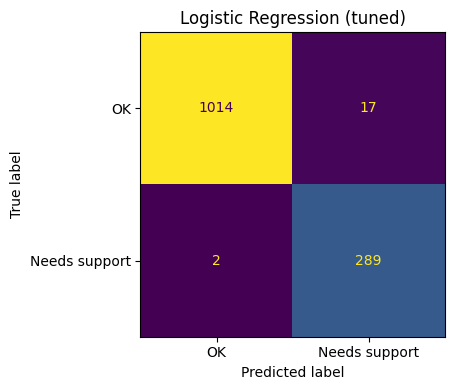


                       Model  Accuracy  Precision  Recall    F1  ROC-AUC
Logistic Regression (tuned)     0.986      0.944   0.993 0.968    0.998


In [35]:
pred = best_model.predict(X_test)
proba = best_model.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=["OK", "Needs support"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["OK", "Needs support"], ax=ax, colorbar=False)
ax.set_title("Logistic Regression (tuned)")
plt.tight_layout(); plt.show()

metrics = pd.DataFrame([{
    "Model": "Logistic Regression (tuned)",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
    "ROC-AUC": roc_auc_score(y_test, proba),
}])
print("\n", metrics.round(3).to_string(index=False))

## Why Logistic Regression?
Logistic Regression was chosen after an initial comparison with a Decision Tree (depth 4). On the same held-out test set it clearly won:


Reasons for choosing it:
- **Best recall (1.00):** the main goal is to *not miss* students who need support, and Logistic Regression caught all of them in the test set. The Decision Tree missed about 16 %.
- **Better overall quality:** much higher precision, F1 and ROC-AUC, so far fewer false alarms as well.
- **Fits the data:** the strongest signals (Attendance, Hours Studied, Previous Scores) relate to exam performance in a roughly linear way, which is exactly what a linear model captures well. A shallow tree has to approximate this with a few coarse splits.
- **Probabilistic output:** it gives a smooth risk probability for each student, which is useful for ranking students and for adjusting the alert threshold later.
- **Interpretable and stable:** coefficients show the direction and size of each factor's effect, and the model is less prone to overfitting than a tree. It is also fast to train and easy to deploy.
- **Handles imbalance:** `class_weight="balanced"` makes up for the 78 / 22 class split.


---
# 10. Export the Model
The whole tuned pipeline (preprocessing + Logistic Regression) is saved with `joblib`, so new data can be passed in raw, without repeating any preprocessing.

In [36]:
MODEL_PATH = "student_risk_logreg_model.joblib"

# Save the full pipeline
joblib.dump(best_model, MODEL_PATH)
print(f"Model saved to: {MODEL_PATH}")

# Reload and verify it gives identical predictions
loaded_model = joblib.load(MODEL_PATH)
assert (loaded_model.predict(X_test) == best_model.predict(X_test)).all()
print("Reloaded model verified: predictions match.")

Model saved to: student_risk_logreg_model.joblib
Reloaded model verified: predictions match.
